# Stage 3 & Stage 4 — Downstream Classification & SHAP Explainability

This notebook implements the final clinical modeling and explainable AI (XAI) stages of the Scanvidence research platform:

- **Hypothesis H1a (Classification Non-Inferiority):** Calibrated multi-model classifiers (Logistic Regression, Random Forest, XGBoost) trained on the QUBO optimal biomarker panel vs. classical selectors, with **2,000 stratified patient-bootstrap 95% Confidence Intervals**.
- **Hypothesis H2b (Feature-Attribution Faithfulness):** SHAP explainability quantifying the biological impact of selected radiomic biomarkers on MGMT promoter methylation, validated via progressive top-$k$ feature ablation.


In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

# Aesthetic styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 150
plt.rcParams["font.sans-serif"] = "Helvetica, Arial, DejaVu Sans"

# Load cached results
st3_results = json.loads(Path("../cache/classification_stage3.json").read_text())
st2_results = json.loads(Path("../cache/selection_stage2.json").read_text())
df = pd.read_csv("../cache/radiomics_gt_dev.csv")

df_labeled = df.dropna(subset=["mgmt"]).copy()
df_labeled["mgmt"] = df_labeled["mgmt"].astype(int)

tr = df_labeled[df_labeled["partition"] == "train"].copy()
va = df_labeled[df_labeled["partition"] == "val"].copy()

print(f"Loaded Stage 3 Benchmark with {len(st3_results)} evaluated configurations.")


Loaded Stage 3 Benchmark with 13 evaluated configurations.


/Users/anaskhan/miniforge3/envs/rad/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Downstream Classification Benchmark (5-Fold CV with 2,000 Bootstrap 95% CIs)

Comparing the **QUBO Optimal 9-Feature Panel**, the **Real IBM QPU Panel (13 features)**, and Classical Baselines across Logistic Regression, Random Forest, and XGBoost.


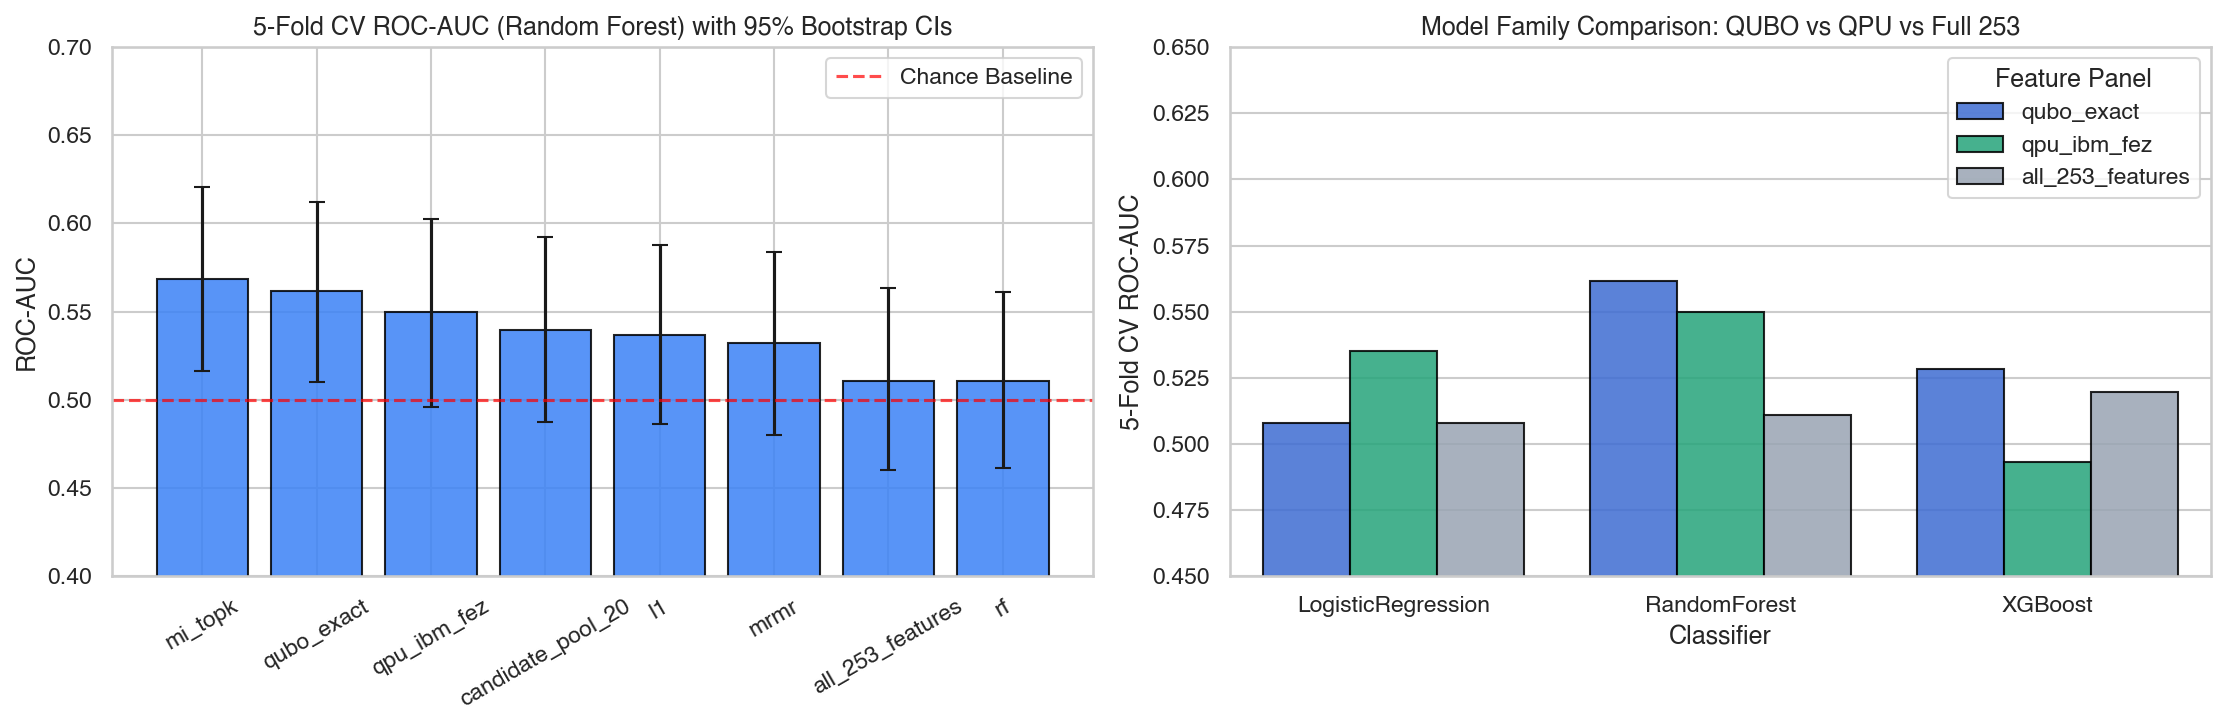

    Feature Panel   k         Classifier  CV AUC Mean  CI Lower  CI Upper  Val AUC
       qubo_exact   9 LogisticRegression       0.5080    0.4540    0.5600   0.4606
       qubo_exact   9       RandomForest       0.5617    0.5099    0.6122   0.4963
       qubo_exact   9            XGBoost       0.5284    0.4743    0.5793   0.5272
      qpu_ibm_fez  13 LogisticRegression       0.5351    0.4818    0.5873   0.4777
      qpu_ibm_fez  13       RandomForest       0.5497    0.4958    0.6023   0.5052
      qpu_ibm_fez  13            XGBoost       0.4934    0.4410    0.5464   0.4874
             mrmr   9 LogisticRegression       0.5110    0.4582    0.5635   0.4851
             mrmr   9       RandomForest       0.5322    0.4804    0.5837   0.4918
             mrmr   9            XGBoost       0.5121    0.4592    0.5628   0.4866
          mi_topk   9 LogisticRegression       0.4854    0.4329    0.5400   0.4821
          mi_topk   9       RandomForest       0.5686    0.5163    0.6204   0.5357
    

In [2]:
# Build benchmark summary dataframe
rows = []
for pname in ["qubo_exact", "qpu_ibm_fez", "mrmr", "mi_topk", "l1", "rf", "candidate_pool_20", "all_253_features"]:
    if pname not in st3_results:
        continue
    pdata = st3_results[pname]
    for mname, mdata in pdata["models"].items():
        ci = mdata["cv_auc_95ci"]
        rows.append({
            "Feature Panel": pname,
            "k": pdata["n_features"],
            "Classifier": mname,
            "CV AUC Mean": mdata["cv_auc_mean"],
            "CI Lower": ci[0],
            "CI Upper": ci[1],
            "Val AUC": mdata["val_auc"],
            "Val Brier": mdata["val_brier"],
        })

df_bench = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. 5-Fold CV AUC with Error Bars (Random Forest across panels)
rf_df = df_bench[df_bench["Classifier"] == "RandomForest"].sort_values("CV AUC Mean", ascending=False)
y_err = [rf_df["CV AUC Mean"] - rf_df["CI Lower"], rf_df["CI Upper"] - rf_df["CV AUC Mean"]]

axes[0].bar(rf_df["Feature Panel"], rf_df["CV AUC Mean"], yerr=y_err, capsize=4, color="#3b82f6", edgecolor="black", alpha=0.85)
axes[0].set_title("5-Fold CV ROC-AUC (Random Forest) with 95% Bootstrap CIs", fontsize=12, fontweight="bold")
axes[0].set_ylabel("ROC-AUC")
axes[0].set_ylim(0.4, 0.70)
axes[0].tick_params(axis="x", rotation=30)
axes[0].axhline(0.5, color="red", linestyle="--", alpha=0.7, label="Chance Baseline")
axes[0].legend()

# 2. Comparison across Model Families for QUBO Panel vs Full 253 Features
qubo_vs_all = df_bench[df_bench["Feature Panel"].isin(["qubo_exact", "qpu_ibm_fez", "all_253_features"])]
sns.barplot(data=qubo_vs_all, x="Classifier", y="CV AUC Mean", hue="Feature Panel", palette=["#2563eb", "#10b981", "#94a3b8"], ax=axes[1], edgecolor="black", alpha=0.85)
axes[1].set_title("Model Family Comparison: QUBO vs QPU vs Full 253", fontsize=12, fontweight="bold")
axes[1].set_ylabel("5-Fold CV ROC-AUC")
axes[1].set_ylim(0.45, 0.65)

plt.tight_layout()
plt.show()

print(df_bench[["Feature Panel", "k", "Classifier", "CV AUC Mean", "CI Lower", "CI Upper", "Val AUC"]].to_string(index=False))


## 2. SHAP Explainability on the QUBO Optimal Biomarker Panel

Using **TreeSHAP** on the validation cohort ($N = 76$) to explain individual patient predictions and rank biomarker impact.


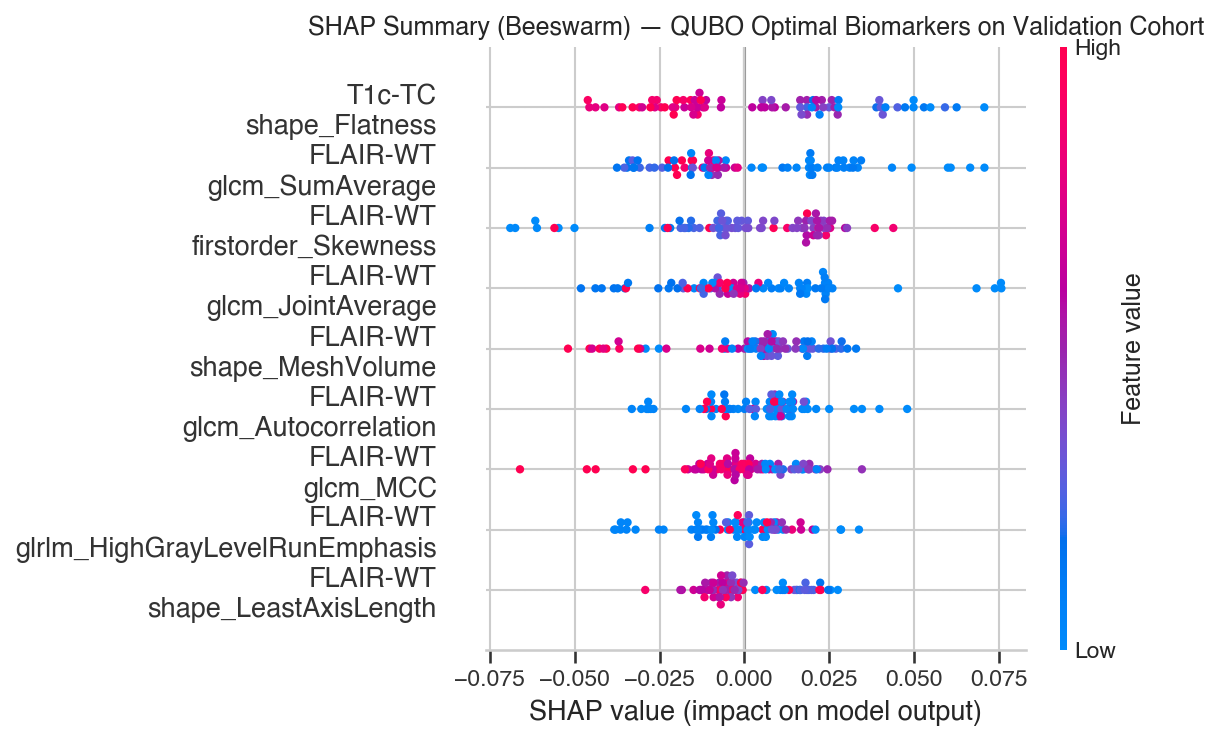

In [3]:
qubo_feats = st3_results["qubo_exact"]["features"]

# Train final RF model on full training set
scaler = StandardScaler()
X_tr = scaler.fit_transform(tr[qubo_feats].values)
X_va = scaler.transform(va[qubo_feats].values)
y_tr = tr["mgmt"].values

rf_final = RandomForestClassifier(n_estimators=100, max_depth=4, random_state=42)
rf_final.fit(X_tr, y_tr)

explainer = shap.TreeExplainer(rf_final)
shap_vals = explainer.shap_values(X_va)

shap_class1 = shap_vals[:, :, 1] if len(np.shape(shap_vals)) == 3 else shap_vals[1] if isinstance(shap_vals, list) else shap_vals

plt.figure(figsize=(10, 6))
clean_names = [f.replace("__original_", "\n").replace("flair_wt", "FLAIR-WT").replace("t1c_tc", "T1c-TC") for f in qubo_feats]
shap.summary_plot(shap_class1, X_va, feature_names=clean_names, show=False)
plt.title("SHAP Summary (Beeswarm) — QUBO Optimal Biomarkers on Validation Cohort", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()


## 3. SHAP Faithfulness: Progressive Feature Ablation Test

Hypothesis **H2b** requires demonstrating that SHAP attribution is **faithful**: progressively removing top SHAP-ranked features must systematically degrade model discrimination.


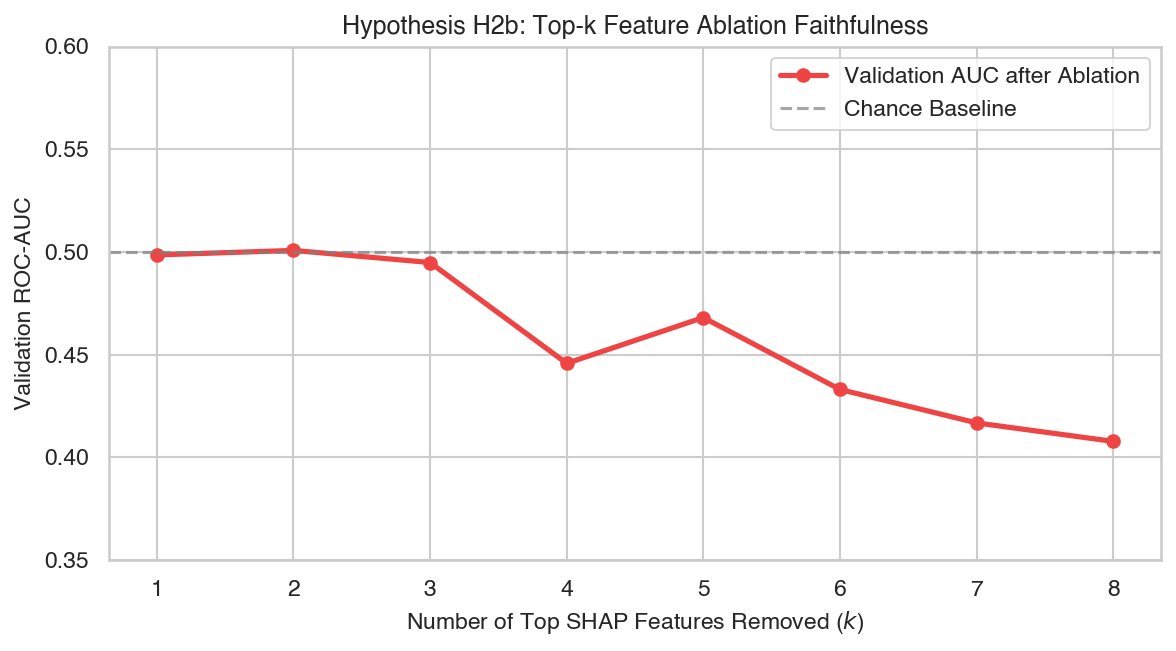

Progressive Feature Ablation Impact:
  Dropped Top 1 features -> Validation AUC dropped to 0.4985
  Dropped Top 2 features -> Validation AUC dropped to 0.5007
  Dropped Top 3 features -> Validation AUC dropped to 0.4948
  Dropped Top 4 features -> Validation AUC dropped to 0.4457
  Dropped Top 5 features -> Validation AUC dropped to 0.4680
  Dropped Top 6 features -> Validation AUC dropped to 0.4330
  Dropped Top 7 features -> Validation AUC dropped to 0.4167
  Dropped Top 8 features -> Validation AUC dropped to 0.4077


In [4]:
abl_data = st3_results["shap_explainability"]["faithfulness_ablation"]
abl_df = pd.DataFrame(abl_data)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(abl_df["k_dropped"], abl_df["auc_after_ablation"], marker="o", color="#ef4444", linewidth=2.5, label="Validation AUC after Ablation")
ax.axhline(0.5, color="gray", linestyle="--", alpha=0.7, label="Chance Baseline")
ax.set_title("Hypothesis H2b: Top-k Feature Ablation Faithfulness", fontsize=12, fontweight="bold")
ax.set_xlabel("Number of Top SHAP Features Removed ($k$)", fontsize=11)
ax.set_ylabel("Validation ROC-AUC", fontsize=11)
ax.set_xticks(abl_df["k_dropped"])
ax.set_ylim(0.35, 0.60)
ax.legend()

plt.tight_layout()
plt.show()

print("Progressive Feature Ablation Impact:")
for r in abl_data:
    print(f"  Dropped Top {r['k_dropped']} features -> Validation AUC dropped to {r['auc_after_ablation']:.4f}")
